In [1]:
import pandas as pd

In [2]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [4]:
total_charges_numeric = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Invalid TotalCharges values:", total_charges_numeric.isna().sum())

Invalid TotalCharges values: 11


In [5]:
df.loc[total_charges_numeric.isna(), ["tenure", "TotalCharges", "Churn"]]

,tenure,TotalCharges,Churn
488,0,,No
753,0,,No
936,0,,No
1082,0,,No
1340,0,,No
3331,0,,No
3826,0,,No
4380,0,,No
5218,0,,No
6670,0,,No


In [6]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

print("Missing values:", df["TotalCharges"].isna().sum())
print("Data type:", df["TotalCharges"].dtype)
print("Total customers:", len(df))

Missing values: 0
Data type: float64
Total customers: 7043


In [7]:
print("Customer Churn Counts:")
print(df["Churn"].value_counts())

print("\nCustomer Churn Percentages:")
print(df["Churn"].value_counts(normalize=True) * 100)

Customer Churn Counts:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Customer Churn Percentages:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [8]:
contract_churn = (
    df.groupby("Contract")["Churn"]
    .apply(lambda x: (x == "Yes").mean() * 100)
    .round(2)
    .sort_values(ascending=False)
)

print("Churn Rate by Contract Type:")
print(contract_churn)

Churn Rate by Contract Type:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


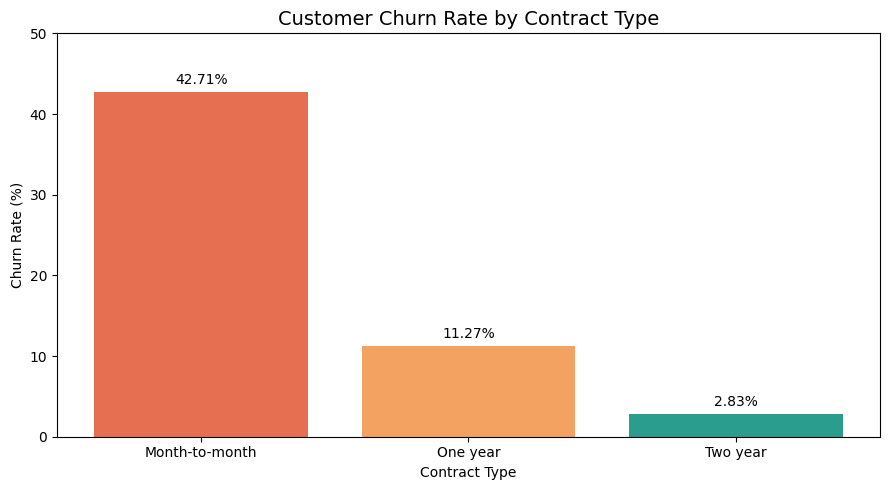

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    contract_churn.index,
    contract_churn.values,
    color=["#E76F51", "#F4A261", "#2A9D8F"]
)

plt.title("Customer Churn Rate by Contract Type", fontsize=14)
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.ylim(0, 50)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{bar.get_height():.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [10]:
monthly_churn = df.groupby("Churn")["MonthlyCharges"].mean().round(2)

print("Average Monthly Charges by Churn Status:")
print(monthly_churn)

Average Monthly Charges by Churn Status:
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


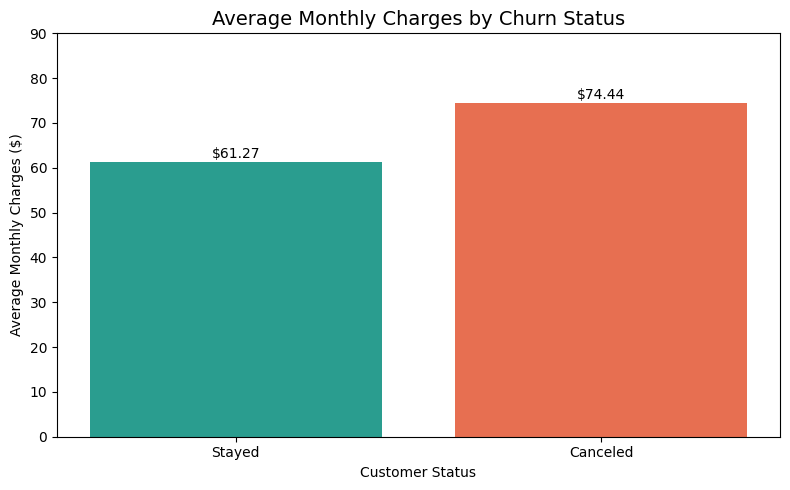

In [11]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Stayed", "Canceled"],
    monthly_churn.values,
    color=["#2A9D8F", "#E76F51"]
)

plt.title("Average Monthly Charges by Churn Status", fontsize=14)
plt.xlabel("Customer Status")
plt.ylabel("Average Monthly Charges ($)")
plt.ylim(0, 90)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"${bar.get_height():.2f}",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [12]:
tenure_churn = df.groupby("Churn")["tenure"].mean().round(1)

print("Average Customer Tenure by Churn Status:")
print(tenure_churn)

Average Customer Tenure by Churn Status:
Churn
No     37.6
Yes    18.0
Name: tenure, dtype: float64


In [13]:
X = df.drop(columns=["customerID", "Churn"])

y = df["Churn"].map({"No": 0, "Yes": 1})

print("Number of customers:", X.shape[0])
print("Number of features:", X.shape[1])
print("\nTarget values:")
print(y.value_counts())

Number of customers: 7043
Number of features: 19

Target values:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))

Training customers: 5634
Testing customers: 1409


In [15]:
numeric_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Data preprocessor created successfully!")

Data preprocessor created successfully!


In [17]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [18]:
from sklearn.metrics import accuracy_score

y_pred = logistic_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Logistic Regression Accuracy: {accuracy * 100:.2f}%")

Logistic Regression Accuracy: 80.55%


In [19]:
from sklearn.metrics import classification_report

print("Logistic Regression Classification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Stayed", "Canceled"]
))

Logistic Regression Classification Report:
              precision    recall  f1-score   support

      Stayed       0.85      0.89      0.87      1035
    Canceled       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



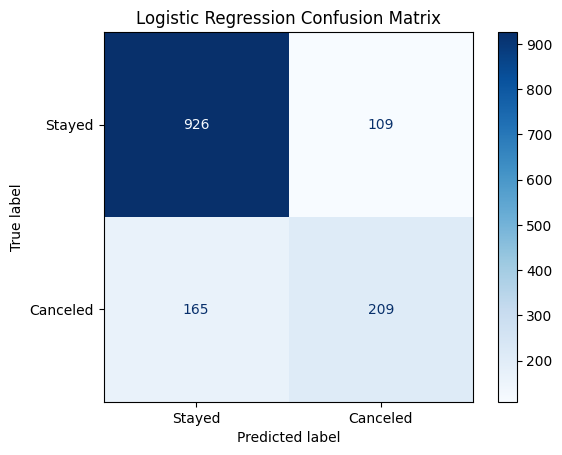

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Stayed", "Canceled"],
    cmap="Blues"
)

plt.title("Logistic Regression Confusion Matrix")
plt.show()

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

random_forest_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [22]:
rf_pred = random_forest_model.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")

print("\nRandom Forest Classification Report:")
print(classification_report(
    y_test,
    rf_pred,
    target_names=["Stayed", "Canceled"]
))

Random Forest Accuracy: 78.28%

Random Forest Classification Report:
              precision    recall  f1-score   support

      Stayed       0.82      0.89      0.86      1035
    Canceled       0.62      0.47      0.54       374

    accuracy                           0.78      1409
   macro avg       0.72      0.68      0.70      1409
weighted avg       0.77      0.78      0.77      1409



In [23]:
from sklearn.metrics import precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, rf_pred)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, rf_pred)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, rf_pred)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, rf_pred)
    ]
})

comparison.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.806,0.657,0.559,0.604
1,Random Forest,0.783,0.619,0.473,0.536


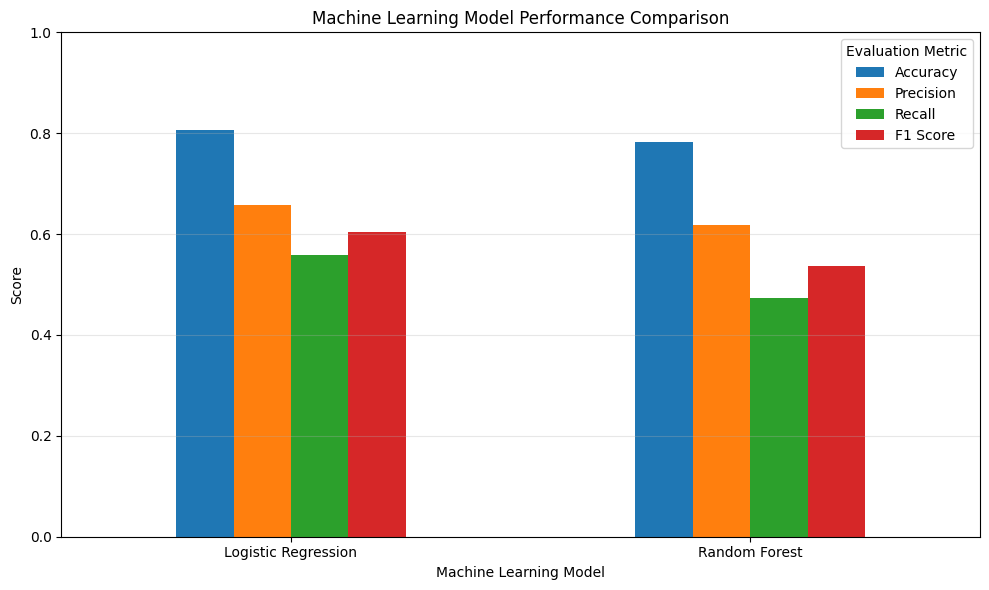

In [24]:
import matplotlib.pyplot as plt

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

plt.title("Machine Learning Model Performance Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Evaluation Metric")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [25]:
from sklearn.inspection import permutation_importance

importance_results = permutation_importance(
    logistic_model,
    X_test,
    y_test,
    scoring="f1",
    n_repeats=5,
    random_state=42
)

feature_importance = pd.Series(
    importance_results.importances_mean,
    index=X_test.columns
).sort_values(ascending=False)

print("Top 10 Most Important Features:")
print(feature_importance.head(10).round(4))

Top 10 Most Important Features:
tenure              0.2366
InternetService     0.1410
Contract            0.1195
OnlineSecurity      0.0364
TechSupport         0.0349
MonthlyCharges      0.0271
StreamingMovies     0.0245
OnlineBackup        0.0240
DeviceProtection    0.0209
PaymentMethod       0.0201
dtype: float64


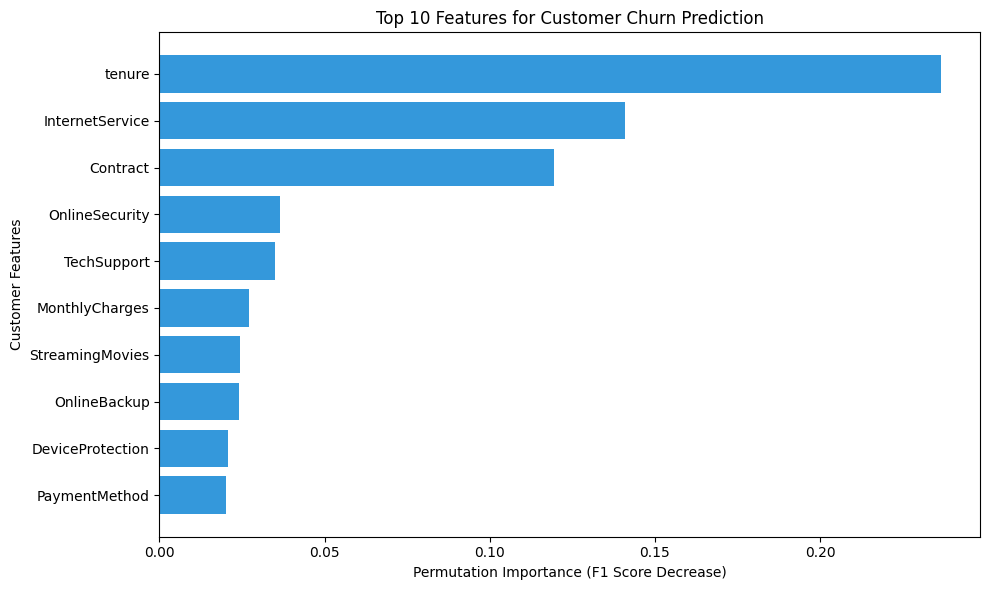

In [26]:
top_features = feature_importance.head(10).sort_values()

plt.figure(figsize=(10, 6))

plt.barh(
    top_features.index,
    top_features.values,
    color="#3498db"
)

plt.title("Top 10 Features for Customer Churn Prediction")
plt.xlabel("Permutation Importance (F1 Score Decrease)")
plt.ylabel("Customer Features")

plt.tight_layout()
plt.show()

In [27]:
sample_customer = X_test.iloc[[0]]

prediction = logistic_model.predict(sample_customer)[0]
probability = logistic_model.predict_proba(sample_customer)[0, 1]

print("Customer Information:")
display(sample_customer[[
    "tenure",
    "Contract",
    "InternetService",
    "MonthlyCharges"
]])

print("\nPredicted Status:", "Canceled" if prediction == 1 else "Stayed")
print(f"Estimated Churn Probability: {probability * 100:.2f}%")

Customer Information:


,tenure,Contract,InternetService,MonthlyCharges
437,72,Two year,Fiber optic,114.05



Predicted Status: Stayed
Estimated Churn Probability: 4.59%


In [28]:
custom_customer = sample_customer.copy()

custom_customer["tenure"] = 2
custom_customer["Contract"] = "Month-to-month"
custom_customer["TotalCharges"] = 228.10

custom_prediction = logistic_model.predict(custom_customer)[0]
custom_probability = logistic_model.predict_proba(custom_customer)[0, 1]

print("Custom Customer Prediction:")
print("Predicted Status:", "Canceled" if custom_prediction == 1 else "Stayed")
print(f"Estimated Churn Probability: {custom_probability * 100:.2f}%")

Custom Customer Prediction:
Predicted Status: Stayed
Estimated Churn Probability: 49.25%


In [29]:
valid_contracts = ["Month-to-month", "One year", "Two year"]

def predict_customer(tenure, contract, monthly_charges):
    if contract not in valid_contracts:
        print("Invalid contract type!")
        print("Please choose:", valid_contracts)
        return

    customer = sample_customer.copy()

    customer["tenure"] = tenure
    customer["Contract"] = contract
    customer["MonthlyCharges"] = monthly_charges
    customer["TotalCharges"] = tenure * monthly_charges

    probability = logistic_model.predict_proba(customer)[0, 1]
    prediction = logistic_model.predict(customer)[0]

    print("Customer Churn Prediction")
    print("Predicted Status:", "Canceled" if prediction == 1 else "Stayed")
    print(f"Estimated Churn Probability: {probability * 100:.2f}%")



In [30]:
import ipywidgets as widgets
from ipywidgets import interact_manual

interact_manual(
    predict_customer,
    tenure=widgets.IntSlider(
        value=12,
        min=0,
        max=72,
        description="Tenure:"
    ),
    contract=widgets.Dropdown(
        options=valid_contracts,
        value="Month-to-month",
        description="Contract:"
    ),
    monthly_charges=widgets.FloatSlider(
        value=75,
        min=0,
        max=150,
        step=1,
        description="Monthly $:"
    )
)

interactive(children=(IntSlider(value=12, description='Tenure:', max=72), Dropdown(description='Contract:', op…

<function __main__.predict_customer(tenure, contract, monthly_charges)>

## Project Summary

### Project Overview
This project uses machine learning to predict whether telecommunications customers are likely to cancel their service.

### Dataset
- 7,043 customer records
- 19 features used for prediction
- 80% training data and 20% testing data

### Machine Learning Models
I trained and compared two machine learning models:

- Logistic Regression: 80.55% accuracy
- Random Forest: 78.28% accuracy

Logistic Regression performed better across accuracy, precision, recall, and F1 score.

### Key Findings
- Customers with month-to-month contracts had higher cancellation rates.
- Customers who canceled had higher average monthly charges.
- Customers who canceled had shorter average tenure.
- Tenure, internet service, and contract type were the most important predictive features.

### Interactive Prediction Tool
I developed an interactive tool using Python and ipywidgets that allows users to adjust customer tenure, contract type, and monthly charges to generate churn predictions.

The demonstration uses the remaining characteristics from an existing sample customer and estimates total charges.

### Conclusion
This project demonstrates how Python, data analysis, visualization, and machine learning can help identify customers who may be at risk of canceling their service.

The best model achieved 80.55% accuracy, although its recall for canceled customers was approximately 56%, leaving room for improvement.